# 10 — Perfil del hospital: qué pasa con quien llega

## Qué contesta este cuaderno

**¿Qué hospital es el SES Hospital Universitario de Caldas?** Qué fracción de quienes piden triage
se atiende aquí, dónde se atiende, por qué causa, qué diagnósticos tienen y por qué se remite al
resto. Saberlo dice **qué factores externos deberían importarle** al conteo del triage.

## El contexto, en palabras del superior del propietario (2026-09-29)

- **Aquí se recibe de todo.** Una urgencia se atiende por razones legales y morales. Otra cosa es
  que se pueda resolver aquí.
- **Donde falta el especialista, se estabiliza y se remite.** Los niños van al Hospital Infantil,
  que no tiene urgencias de puerta. Lo cardiovascular, a una clínica especializada.
- **Los accidentes de tránsito** van al hospital más cercano, en ambulancia. Sin SOAT, por la EPS a
  donde haya convenio.
- «**Es mejor remitirlo que tratarlo con limitaciones.**»

## Cómo se protege a las personas

- **Solo conteos agregados**: por mes, semana o año, y por categorías de catálogo (área,
  capítulo CIE-10, motivo de remisión). **Ninguna fila corresponde a un paciente.** Los ingresos,
  folios y diagnósticos se unen dentro de la base y solo sale el conteo.
- **Toda casilla con menos de 5 casos está oculta** y marcada como suprimida. Por eso algunas sumas
  son un poco menores que el total real.
- Nada de texto libre: ni el motivo de consulta ni el motivo escrito de la remisión.
- Las columnas sensibles de las 14 tablas se declararon en `extraccion/__init__.py` **antes** de
  consultar nada. Protocolo en `docs/CONTEXTO.md`, 2026-09-29.

## De dónde salen los datos

| Tabla | Qué es | Cómo se genera |
|---|---|---|
| `salidas/perfil_ingreso_banda.parquet`, `perfil_ingreso_nivel.parquet` | Triages por mes que pasan o no a ingreso, por edad y por nivel | `python -m extraccion --perfil` |
| `salidas/perfil_area_mensual.parquet` | Ingresos por mes y área de servicio (catálogo `AREA_SERVICIO`) | ídem |
| `salidas/perfil_causa_mensual.parquet` | Ingresos por mes y causa de ingreso (código; la base no trae catálogo) | ídem |
| `salidas/perfil_dx_*.parquet` | Diagnóstico principal CIE-10 del ingreso, por capítulo o código | ídem; capítulos en `extraccion/cie10.py` |
| `salidas/perfil_remisiones_*.parquet` | Remisiones por motivo (catálogo de 6 valores) y servicio | ídem |


In [1]:
import sys, pathlib, warnings
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from matplotlib import pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
CATEG = [AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO]
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
SECUENCIAL = LinearSegmentedColormap.from_list("seq", ["#f0efec", "#86b6ef", "#2a78d6", "#104281"])
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})
S = RAIZ / "salidas"
leer = lambda n: pd.read_parquet(S / f"{n}.parquet")
ib, iv = leer("perfil_ingreso_banda"), leer("perfil_ingreso_nivel")
area, causa = leer("perfil_area_mensual"), leer("perfil_causa_mensual")
dxs, dxe, dxc = leer("perfil_dx_semanal"), leer("perfil_dx_edad_anual"), leer("perfil_dx_codigo_mensual")
rm, rs = leer("perfil_remisiones_motivo"), leer("perfil_remisiones_servicio")
for t in (ib, iv, area, causa, dxc, rm):
    t["mes"] = pd.to_datetime(t["mes"]); t["anio"] = t["mes"].dt.year
dxs["semana"] = pd.to_datetime(dxs["semana"])
print("casillas ocultas por tabla (%):", {n: round(100 * t["suprimido"].mean(), 1) for n, t in
      [("ingreso×edad", ib), ("ingreso×nivel", iv), ("área", area), ("causa", causa), ("dx semanal", dxs),
       ("dx×edad", dxe), ("remisión×motivo", rm), ("remisión×servicio", rs)]})
print("periodo:", ib.mes.min().date(), "a", ib.mes.max().date(), "(el último mes está incompleto)")


casillas ocultas por tabla (%): {'ingreso×edad': 6.7, 'ingreso×nivel': 30.7, 'área': 36.1, 'causa': 25.2, 'dx semanal': 20.6, 'dx×edad': 22.4, 'remisión×motivo': 33.3, 'remisión×servicio': 6.8}
periodo: 2020-01-01 a 2026-09-01 (el último mes está incompleto)


---
# 1. De la puerta al ingreso

Un triage **pasa a ingreso** cuando el hospital toma al paciente. Si no pasa, se orienta a otro lugar: su EPS, consulta externa u otra institución. Es la frontera entre «llegó» y «se atiende aquí».

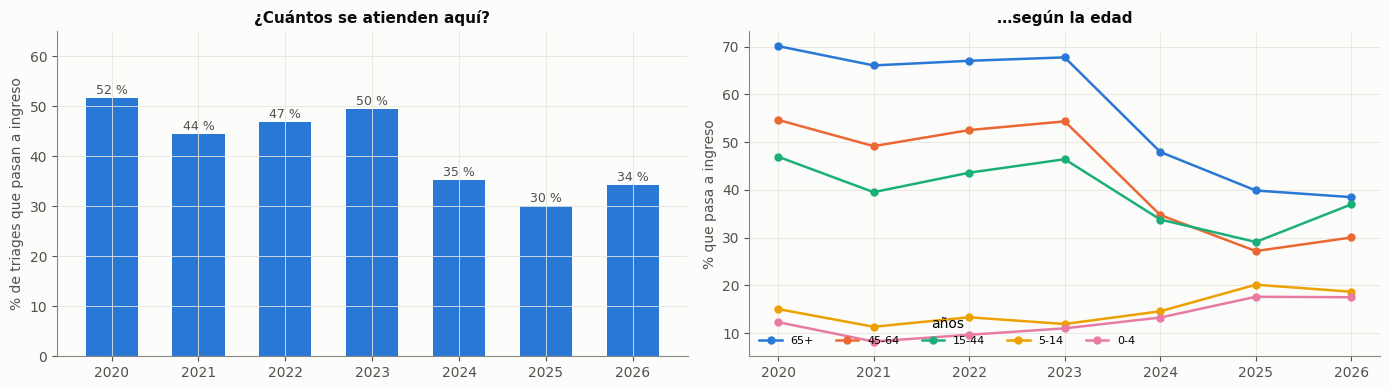

,triages,con ingreso,% con ingreso
anio,,,
2020,38659.0,19937.0,51.6
2021,54494.0,24215.0,44.4
2022,69206.0,32452.0,46.9
2023,70215.0,34743.0,49.5
2024,82379.0,28989.0,35.2
2025,72838.0,21854.0,30.0
2026,47121.0,16175.0,34.3


con_ingreso,triages,% con ingreso
nivel,,
II,6419.0,94.7
IIIU,106910.0,93.1
I,1324.0,92.5
II-G,6321.0,66.6
III-G,47492.0,64.4
III,42193.0,29.7
IV-G,151.0,18.5
IV,170159.0,14.0
M,117.0,0.0


In [2]:
a = ib.groupby(["anio", "con_ingreso"]).n.sum().unstack()
tot = a.sum(axis=1); pct_ing = (100 * a[1] / tot).round(1)
por_banda = ib.groupby(["anio", "banda", "con_ingreso"]).n.sum().unstack()
pb = (100 * por_banda[1] / por_banda.sum(axis=1)).unstack()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(pct_ing.index, pct_ing.values, color=AZUL, width=.6)
for x, v in pct_ing.items(): axes[0].text(x, v + .8, f"{v:.0f} %", ha="center", fontsize=9, color=TINTA2)
axes[0].set_ylabel("% de triages que pasan a ingreso"); axes[0].set_title("¿Cuántos se atienden aquí?"); axes[0].set_ylim(0, 65)
orden = ["65-+", "45-64", "15-44", "5-14", "0-4"]
for i, b in enumerate(orden):
    if b in pb: axes[1].plot(pb.index, pb[b], marker="o", ms=5, color=CATEG[i], lw=1.8, label={"65-+": "65+"}.get(b, b))
axes[1].set_ylabel("% que pasa a ingreso"); axes[1].set_title("…según la edad"); axes[1].legend(title="años", ncol=5, loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()
niv = iv.groupby(["nivel", "con_ingreso"]).n.sum().unstack().fillna(0)
niv["triages"] = niv.sum(axis=1); niv["% con ingreso"] = (100 * niv[1] / niv.triages).round(1)
display(pd.DataFrame({"triages": tot, "con ingreso": a[1], "% con ingreso": pct_ing}))
niv.loc[niv.triages >= 100, ["triages", "% con ingreso"]].sort_values("% con ingreso", ascending=False)


## Lectura

**El SES recibe a todos, pero se queda con una parte, y esa parte se ha achicado.**

| | 2020 | 2021 | 2022 | 2023 | 2024 | 2025 | 2026 |
|---|---|---|---|---|---|---|---|
| % de triages que pasan a ingreso | 51,6 | 44,4 | 46,9 | 49,5 | **35,2** | **30,0** | 34,3 |

- **De 2023 a 2025 la fracción que se atiende aquí cae de la mitad a menos de un tercio.** Coincide
  con la reclasificación del nivel de triage (cuaderno 01) y con la crisis de Nueva EPS. El hospital
  sigue recibiendo, pero orienta a más gente hacia afuera.
- **La edad lo confirma, como dijo el superior.** Los mayores de 65 son los que más se quedan; los
  niños de 0-4 y 5-14, los que menos: se estabilizan y se remiten al Hospital Infantil.
- **El nivel de triage es, en la práctica, la decisión de tomar o no:**
  - I, II y IIIU: 92-95 % pasan a ingreso;
  - III-G y II-G, obstétricos: 64-67 %;
  - III: 30 %;
  - **IV: 14 %; V: 0 %.**

**Límite.** «Pasar a ingreso» dice que el hospital lo tomó, no cuánto tiempo ni con qué desenlace.
Una casilla con menos de 5 casos está oculta, así que las sumas son ligeramente menores que el
total real.

---
# 2. Dónde se atiende y por qué causa

Área de servicio del ingreso (catálogo del hospital) y **causa de ingreso**. La causa viene en códigos sin catálogo en la base, y **no existe diccionario** (confirmado por el propietario). Solo se rotulan los tres códigos descifrados con evidencia, cruzando con el asegurador del triage: el código 6 (74 % SOAT) es accidente de tránsito, el 10 (74 % ARL) accidente laboral y el 3 enfermedad general. Los demás quedan como «código N».

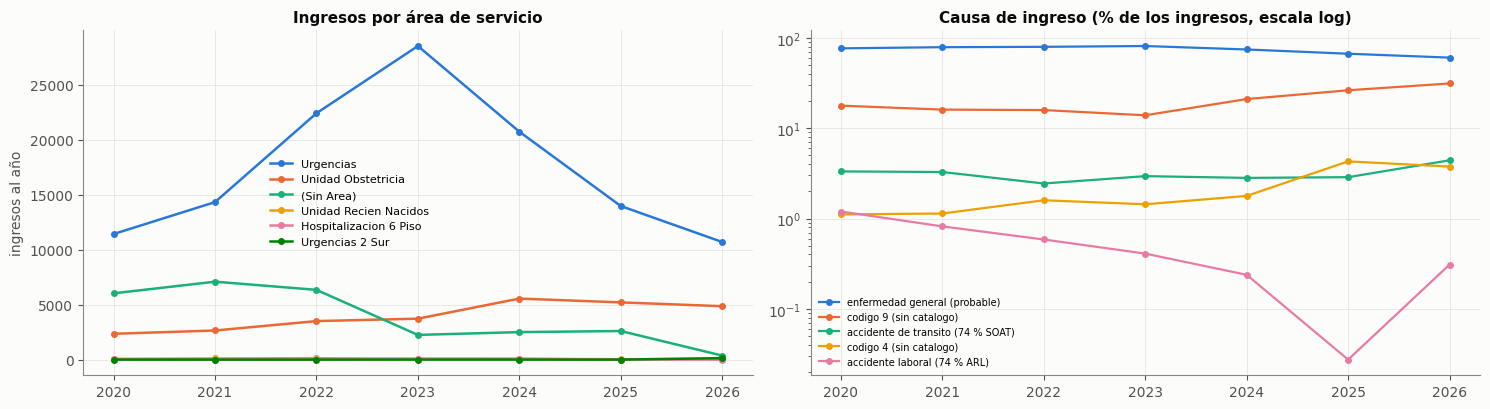

2026 va hasta septiembre (incompleto).


area,URGENCIAS,UNIDAD OBSTETRICIA,(sin area),UNIDAD RECIEN NACIDOS,HOSPITALIZACION 6 PISO,URGENCIAS 2 SUR
anio,,,,,,
2020,11431,2349,6032,70,27,0
2021,14336,2649,7092,107,6,0
2022,22423,3505,6349,128,11,0
2023,28544,3726,2247,72,79,0
2024,20746,5554,2502,69,74,0
2025,13979,5207,2601,32,0,0
2026,10705,4862,365,58,0,131


causa,enfermedad general (probable),codigo 9 (sin catalogo),accidente de transito (74 % SOAT),codigo 4 (sin catalogo),accidente laboral (74 % ARL),codigo 2 (sin catalogo),codigo 1 (sin catalogo),codigo 7 (sin catalogo),codigo 8 (sin catalogo),codigo 11 (sin catalogo),codigo 5 (sin catalogo)
anio,,,,,,,,,,,
2020,15201,3531,661,221,238,50,0,0,5,0,0
2021,19028,3879,791,275,198,26,0,0,0,0,0
2022,25720,5137,791,516,190,61,0,0,0,0,0
2023,28125,4816,1022,499,142,98,10,0,0,0,0
2024,21477,6076,815,515,69,0,0,0,0,0,0
2025,14534,5727,626,936,6,0,0,0,0,0,0
2026,9743,5042,712,607,50,0,0,5,0,0,0


In [3]:
ar = area.groupby(["anio", "area"]).n.sum().unstack().fillna(0)
ar = ar[ar.sum().sort_values(ascending=False).index[:6]]
ca = causa.groupby(["anio", "causa"]).n.sum().unstack().fillna(0)
ca = ca[ca.sum().sort_values(ascending=False).index]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
for i, c in enumerate(ar.columns): axes[0].plot(ar.index, ar[c], marker="o", ms=4, color=CATEG[i], lw=1.8, label=c.title())
axes[0].set_title("Ingresos por área de servicio"); axes[0].set_ylabel("ingresos al año"); axes[0].legend(fontsize=8)
cp = 100 * ca.div(ca.sum(axis=1), axis=0)
for i, c in enumerate([c for c in cp.columns if cp[c].max() >= .3][:7]):
    axes[1].plot(cp.index, cp[c], marker="o", ms=4, color=CATEG[i], lw=1.6, label=c)
axes[1].set_yscale("log"); axes[1].set_title("Causa de ingreso (% de los ingresos, escala log)"); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
print("2026 va hasta septiembre (incompleto).")
display(ar.astype(int))
ca.astype(int)


## Lectura

**Dónde:**
- **Urgencias**: 122 mil ingresos.
- **La unidad obstétrica crece de forma sostenida**: de 2.349 ingresos en 2020 a 5.554 en 2024, y
  ya 4.862 en 2026 a septiembre, mientras Urgencias cae desde 2023. **Una parte creciente de lo que
  se atiende es embarazo y parto**, que no depende del clima ni de las fiestas.
- «Sin área» baja de ~6.000 al año a 365 en 2026: es un problema de registro que se fue corrigiendo.

**Por qué causa:**
- **Enfermedad general** (probable) es el grueso.
- El **código 9, sin catálogo**, es el segundo, con 3.500-6.000 al año, **y su peso crece**: de
  18 % de los ingresos en 2020 a 31 % en 2026. Sin diccionario no se sabe qué es. Es de todos los
  aseguradores, no de uno.
- **Accidentes de tránsito: 600-1.000 al año**, entre 2 y 3 al día. Estable.
- **Accidentes laborales: de 238 en 2020 a 6 en 2025** (50 en 2026). Puede ser real o un cambio
  de cómo se codifica.

**Límite.** Solo los códigos 3, 6 y 10 tienen rótulo, y solo con evidencia indirecta (el cruce con
el asegurador). **No existe diccionario de la base**, confirmado por el propietario.

---
# 3. Qué tienen: el diagnóstico principal

Diagnóstico principal (CIE-10) del primer folio de cada ingreso que viene de un triage. Cubre el **98-99 % de los ingresos**. Es el diagnóstico que pone el médico, no la nota de la enfermera. **Solo describe al grupo que se ingresa**, no a todos los que piden triage.

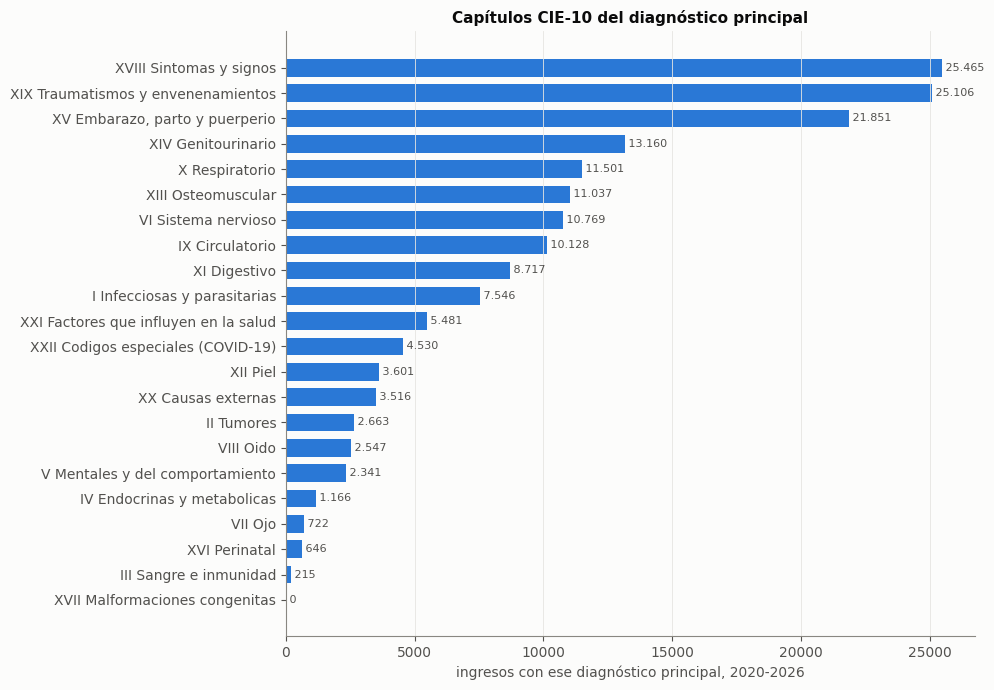

,código,subcódigo más usado,nombre del subcódigo,capítulo,ingresos
0,R10,R101,DOLOR ABDOMINAL LOCALIZADO EN PARTE SUPERIOR ...,XVIII Sintomas y signos,15175
1,G44,G448,OTROS SINDROMES DE CEFALEA ESPECIFICADOS ...,VI Sistema nervioso,5281
2,A09,A09X,DIARREA Y GASTROENTERITIS DE PRESUNTO ORIGEN I...,I Infecciosas y parasitarias,4944
3,M54,M545,LUMBAGO NO ESPECIFICADO ...,XIII Osteomuscular,4647
4,U07,U071,COVID-19 VIRUS IDENTIFICADO,XXII Codigos especiales (COVID-19),4577
5,N39,N390,"INFECCION DE VIAS URINARIAS, SITIO NO ESPECIFI...",XIV Genitourinario,4537
6,R07,R072,DOLOR PRECORDIAL ...,XVIII Sintomas y signos,3856
7,O62,O620,CONTRACCIONES PRIMARIAS INADECUADAS ...,"XV Embarazo, parto y puerperio",3766
8,O47,O470,FALSO TRABAJO DE PARTO ANTES DE LA 37 SEMANAS ...,"XV Embarazo, parto y puerperio",3248
9,G43,G439,"MIGRAÑA, NO ESPECIFICADA ...",VI Sistema nervioso,2572


In [4]:
cap = dxs.assign(anio=dxs.semana.dt.year).groupby(["anio", "capitulo"]).n.sum().unstack().fillna(0)
tot_cap = cap.sum().sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(range(len(tot_cap)), tot_cap.values, color=AZUL, height=.7)
ax.set_yticks(range(len(tot_cap)), tot_cap.index)
for i, v in enumerate(tot_cap.values): ax.text(v, i, f" {v:,.0f}".replace(",", "."), va="center", fontsize=8, color=TINTA2)
ax.set_xlabel("ingresos con ese diagnóstico principal, 2020-2026"); ax.set_title("Capítulos CIE-10 del diagnóstico principal")
ax.grid(axis="y", visible=False); plt.tight_layout(); plt.show()
top = (dxc[~dxc.cod3.str.startswith("(otros")].groupby(["cod3", "subcodigo_mas_usado", "nombre", "capitulo"]).n.sum()
         .sort_values(ascending=False).head(25).reset_index())
top.columns = ["código", "subcódigo más usado", "nombre del subcódigo", "capítulo", "ingresos"]
top


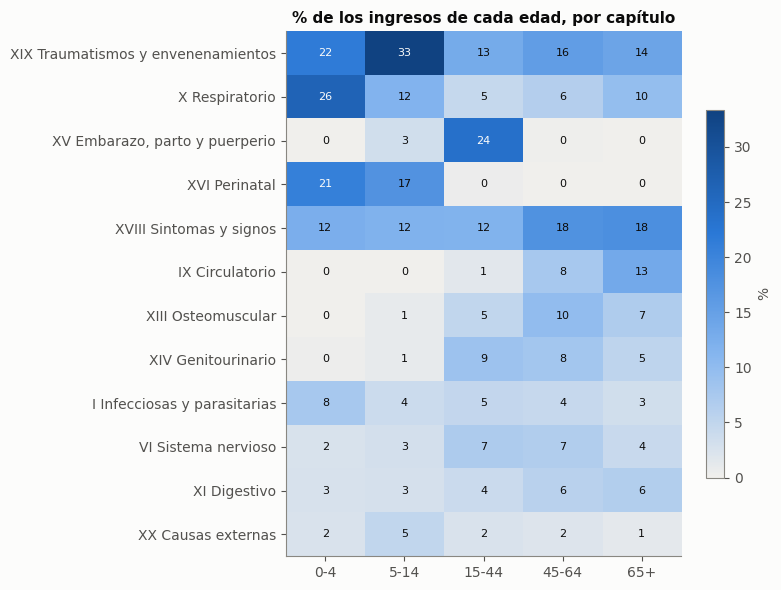

In [5]:
# ¿Qué capítulo pesa en cada edad? (cuota de cada capítulo dentro de la banda, 2020-2026)
e = dxe.groupby(["capitulo", "banda"]).n.sum().unstack().fillna(0)
e = e[[b for b in ["0-4", "5-14", "15-44", "45-64", "65-+"] if b in e]]
cuota = 100 * e / e.sum()
cuota = cuota.loc[cuota.max(axis=1).sort_values(ascending=False).index[:12]]
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(cuota.values, cmap=SECUENCIAL, aspect="auto")
ax.set_xticks(range(cuota.shape[1]), [{"65-+": "65+"}.get(c, c) for c in cuota.columns]); ax.set_yticks(range(len(cuota)), cuota.index)
for i in range(cuota.shape[0]):
    for j in range(cuota.shape[1]):
        v = cuota.iat[i, j]; ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color=TINTA if v < 20 else SUP)
ax.grid(False); ax.set_title("% de los ingresos de cada edad, por capítulo"); fig.colorbar(im, ax=ax, shrink=.7, label="%")
plt.tight_layout(); plt.show()


## Lectura

**Lo que atiende el SES, según el médico** (diagnóstico principal de 176 mil ingresos, 2020-2026):

1. **Síntomas y signos**: dolor abdominal (R10: 15.175), dolor precordial y síncope. Es el paciente
   que llega con un síntoma que hay que estudiar.
2. **Traumatismos**: golpes y contusiones de cabeza, tobillo, muñeca y rodilla. Caídas y golpes,
   no tránsito.
3. **Embarazo y parto**: trabajo de parto, falso trabajo de parto, amenaza de aborto.
4. **Genitourinario**: infección urinaria (N39) y cólico renal.
5. **Respiratorio**: **EPOC exacerbado (J44)** y resfriado común (J00).
6. **Osteomuscular** (lumbago), **neurológico** (cefalea, migraña), circulatorio (hipertensión) y
   diarrea (A09).

**Por edad, el hospital es otro:**
- **niños de 0-4**: respiratorio (26 %), traumatismos (22 %) y perinatal (21 %);
- **5-14**: traumatismos (**33 %**);
- **15-44**: embarazo (24 %), síntomas y traumatismos;
- **65 y más**: síntomas (18 %), traumatismos (14 %), **circulatorio (13 %)** y **respiratorio
  (10 %)**.

**Qué factores externos le deberían importar a cada grupo**, que es lo que el propietario quería
saber:
- **mayores**: frío (EPOC, circulatorio) y virus;
- **niños que se estabilizan aquí**: virus y trauma doméstico;
- **adultos jóvenes**: trauma de fin de semana y embarazo, que no depende del entorno.

**Límites.**
- **Solo describe al grupo que se ingresa** (30-50 % del triage). Lo que se orienta afuera no tiene
  diagnóstico aquí.
- Los nombres son de la **subcategoría más usada** en el hospital dentro de cada código de 3
  caracteres. El catálogo de la base no trae el nombre de la categoría.
- **Rareza para revisar:** «perinatal» aparece en el 17 % de los ingresos de 5-14 años. Clínicamente
  no encaja. Probablemente es cómo se registra la edad en el triage cuando un ingreso agrupa a
  madre y recién nacido. No se interpreta.

---
# 4. Cómo cambia lo que tienen a lo largo del año

Perfil mensual de los capítulos con mecanismo externo conocido: respiratorio, infecciosas (sobre todo diarrea), traumatismos y embarazo, con el síntoma genérico como referencia. Cada año se compara con su propia media (1 = la media del año), así que la caída del volumen no se cuela en el perfil.

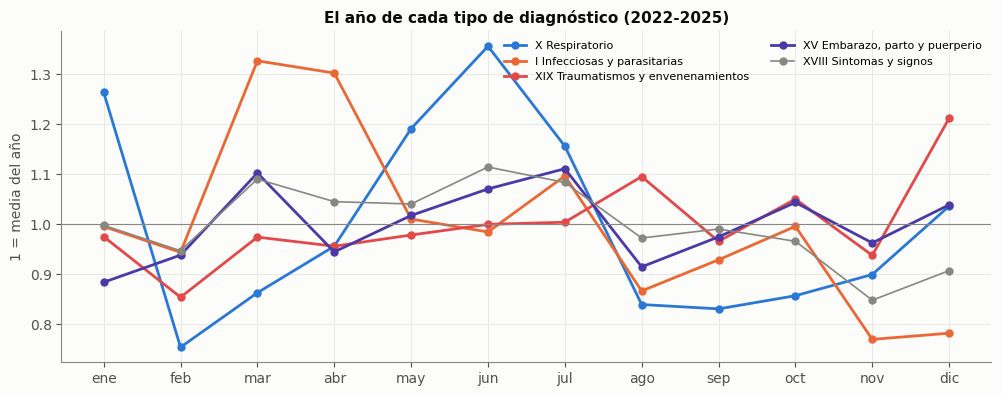

mes,ene,feb,mar,abr,may,jun,jul,ago,sep,oct,nov,dic
X Respiratorio,1.26,0.75,0.86,0.96,1.19,1.36,1.16,0.84,0.83,0.86,0.90,1.04
I Infecciosas y parasitarias,1.00,0.94,1.33,1.30,1.01,0.98,1.10,0.87,0.93,1.00,0.77,0.78
XIX Traumatismos y envenenamientos,0.97,0.85,0.97,0.96,0.98,1.00,1.00,1.10,0.97,1.05,0.94,1.21
"XV Embarazo, parto y puerperio",0.88,0.94,1.10,0.94,1.02,1.07,1.11,0.91,0.97,1.04,0.96,1.04
XVIII Sintomas y signos,1.00,0.95,1.09,1.05,1.04,1.11,1.08,0.97,0.99,0.97,0.85,0.91


In [6]:
sel = {"X Respiratorio": AZUL, "I Infecciosas y parasitarias": NARANJA, "XIX Traumatismos y envenenamientos": ROJO,
       "XV Embarazo, parto y puerperio": VIOLETA, "XVIII Sintomas y signos": MUDO}
m = dxs[dxs.semana.between("2022-01-01", "2025-12-31")].copy()
m["anio"], m["mes"] = m.semana.dt.year, m.semana.dt.month
fig, ax = plt.subplots(figsize=(12, 4.3)); perfiles = {}
for c, col in sel.items():
    s = m[m.capitulo.eq(c)].groupby(["anio", "mes"]).n.sum()
    rel = s / s.groupby(level=0).transform("mean")
    p = rel.groupby(level=1).mean(); perfiles[c] = p.round(2)
    ax.plot(p.index, p.values, marker="o", ms=5, lw=2 if c != "XVIII Sintomas y signos" else 1.2, color=col, label=c)
ax.axhline(1, color=MUDO, lw=.8); ax.set_xticks(range(1, 13), ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"])
ax.set_ylabel("1 = media del año"); ax.set_title("El año de cada tipo de diagnóstico (2022-2025)"); ax.legend(fontsize=8, ncol=2)
plt.show()
pd.DataFrame(perfiles).rename(index=dict(enumerate(["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"], 1))).T


## Lectura

**Cada tipo de diagnóstico tiene su propio año** (1 = media de su año, 2022-2025):

| | Pico | Valle |
|---|---|---|
| **Respiratorio** | **junio (1,36), enero (1,26), mayo (1,19)** | febrero (0,75), agosto-septiembre (0,83-0,84) |
| **Infecciosas (diarrea)** | **marzo-abril (1,30-1,33)** | noviembre-diciembre (0,77-0,78) |
| **Traumatismos** | **diciembre (1,21)**, agosto (1,10) | febrero (0,85) |
| Embarazo | julio (1,11), marzo (1,10) | enero (0,88) |
| Síntomas (referencia) | casi plano | noviembre (0,85) |

- **Lo respiratorio que se atiende sube a mitad de año (mayo-julio) y en enero.** Es la temporada
  que vio el cuaderno 08 en el triage total y que el cuaderno 09 conectó con el frío y la humedad.
  Aquí aparece con el diagnóstico del médico, sin leer una sola nota.
- **El trauma es de diciembre**: la temporada festiva de los cuadernos 08 y 09 (riñas, alcohol,
  pólvora), ahora con diagnóstico.
- **La diarrea es de marzo-abril**: el primer periodo de lluvias. Al menos en el hospital encaja con
  la literatura de «la primera lluvia fuerte», aunque en la ciudad (cuaderno 09) la anomalía de
  lluvia no la precedía.

**Estas son las series de desenlace específico** que el proyecto esperaba del NLP: respiratorio,
diarrea, trauma y embarazo, diarias desde 2020, **con diagnóstico médico y sin procesar texto**. Su
límite es que solo cubren al grupo que se ingresa.

---
# 5. Por qué se remite

`SEGUIMIENTO_REMISIONES_DW`, 2023-2026. El motivo es un **catálogo cerrado de 6 valores**, y se comprueba en cada extracción que lo sigue siendo. El motivo escrito a mano (`MotivoRemision`, ~550 caracteres de texto clínico) **no se consulta nunca**.

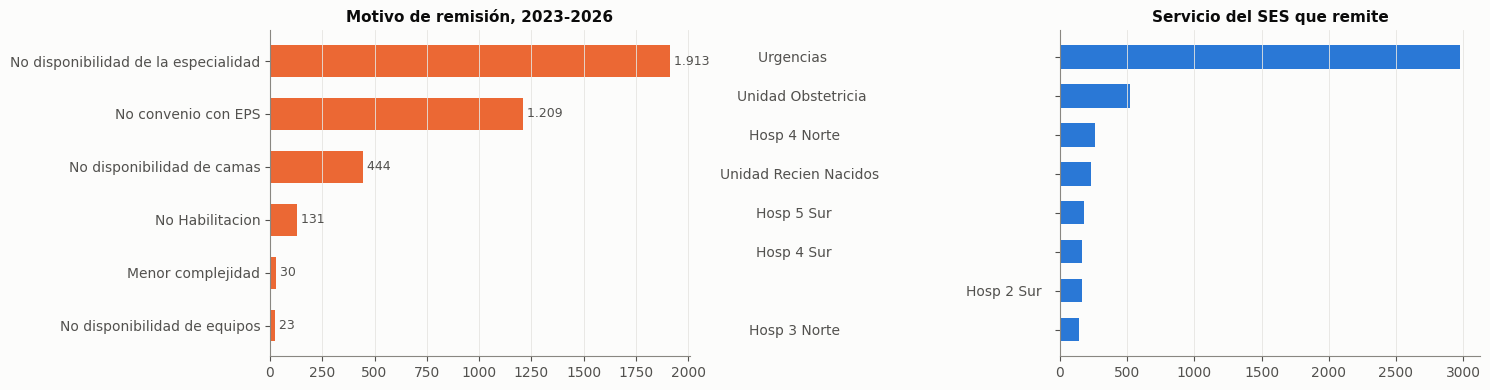

motivo,No disponibilidad de la especialidad,No convenio con EPS,No disponibilidad de camas,No Habilitacion,Menor complejidad,No disponibilidad de equipos
anio,,,,,,
2023,575,331,110,0,8,0
2024,566,371,114,0,10,0
2025,487,360,156,21,12,17
2026,285,147,64,110,0,6


In [7]:
rmo = rm.groupby(["anio", "motivo"]).n.sum().unstack().fillna(0)
rmo = rmo[rmo.sum().sort_values(ascending=False).index]
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
tot_m = rmo.sum().sort_values()
axes[0].barh(range(len(tot_m)), tot_m.values, color=NARANJA, height=.6); axes[0].set_yticks(range(len(tot_m)), tot_m.index)
for i, v in enumerate(tot_m.values): axes[0].text(v, i, f" {v:,.0f}".replace(",", "."), va="center", fontsize=9, color=TINTA2)
axes[0].set_title("Motivo de remisión, 2023-2026"); axes[0].grid(axis="y", visible=False)
srv = rs.groupby("servicio").n.sum().sort_values().tail(8)
axes[1].barh(range(len(srv)), srv.values, color=AZUL, height=.6); axes[1].set_yticks(range(len(srv)), [s.title() for s in srv.index])
axes[1].set_title("Servicio del SES que remite"); axes[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
rmo.astype(int)


## Lectura

**Por qué se remite** (2023-2026):

| Motivo | Remisiones |
|---|---|
| **No hay la especialidad** | 1.913 |
| **No hay convenio con la EPS** | 1.209 |
| No hay camas | 444 |
| **No está habilitado** | 131, casi todo en 2026 |
| Menor complejidad / sin equipos | 53 |

- **Las dos causas grandes son exactamente las que describió el superior:** falta el especialista
  (se estabiliza y se remite) y **la EPS no tiene convenio aquí**. Esta segunda conecta con la crisis
  de Nueva EPS del cuaderno 07.
- **«No habilitación» aparece de golpe en 2025-2026** (0 → 21 → 110). Algún servicio dejó de estar
  habilitado. Es otro hecho institucional que cambia qué puede atender el hospital, y merece
  preguntarse cuál.
- **El 60 % de las remisiones sale de Urgencias**, y le siguen obstetricia, hospitalización y
  recién nacidos.

**Límite.** Son las remisiones que registra este sistema, desde 2023. El destino no se consulta.

---
# 6. Qué hospital es, y qué factores deberían importarle

**El SES es la puerta de urgencias general de Manizales: recibe todo, estabiliza y decide.**
- Se queda con **un tercio** de lo que llega (la mitad hasta 2023).
- Lo que se queda son **adultos y mayores con síntomas por estudiar, trauma, embarazo, infecciones
  urinarias, respiratorio y cefaleas**.
- Remite lo que no puede resolver: **falta de especialista** (niños, cardiovascular) y **falta de
  convenio con la EPS**.

**Qué significa para la pregunta del proyecto** («¿va a subir el triage?»):
1. **El conteo total mide la puerta, y la puerta la mueven la red y el calendario.** Cuánta gente
   llega depende de a dónde manda cada EPS (Nueva EPS, convenios), de la hora y de las noches
   festivas. Es lo que ya mostraron los cuadernos 07 y 08.
2. **Los mecanismos del entorno se ven en lo que se atiende**, y cada uno en su época:
   - **respiratorio** en mayo-julio y enero, sobre todo en niños y mayores. Lo empujan el frío, la
     humedad y los virus (cuaderno 09);
   - **trauma** en diciembre y en fines de semana. Lo empujan la fiesta, el alcohol y las riñas;
   - **diarrea** en marzo-abril, con las primeras lluvias;
   - **embarazo**, que crece y no depende del entorno.
3. **Para el modelo**, dos niveles:
   - **conteo total**: calendario festivo, estado de la red (Nueva EPS, convenios, habilitación) y
     temporada;
   - **series por diagnóstico**, para **probar el mecanismo**: frío × virus × mayores sobre lo
     respiratorio, fiesta sobre el trauma.

   Sin haber leído una nota.

**Lo que no se sabe y convendría preguntar:**
- qué es el **código 9** de causa de ingreso, que crece;
- **qué servicio dejó de estar habilitado** en 2025-2026;
- si el **alza de obstetricia** es de la ciudad o del cierre de otra maternidad de la red.